
# Modeller

**Mål:** Förutsäga antalet uthyrda cyklar per timme.

- **Problemtyp:** Regression
- **Målvariabel:** `Rented Bike Count`
- **Utvärdering:** MAE – genomsnittligt absolut fel



In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/SeoulBikeData.csv", encoding="cp1252")
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

df = df[df["Functioning Day"] == "Yes"].copy()

weather_features = [
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)"
]

target = "Rented Bike Count"
y = df[target]

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42
)



### DummyRegressor – baseline

En modell som alltid förutsäger **medelvärdet från träningsdatan**.

**Varför?** För att undersöka om våra andra modeller faktiskt är bättre än en enkel gissning.

### Baseline MAE: 509,7




## 02 | Linjär regression

Vi testade två varianter:

- **8 vädervariabler**
- **8 vädervariabler + Hour**

Vi undersökte hur mycket mer information kunde förbättra modellens resultat.


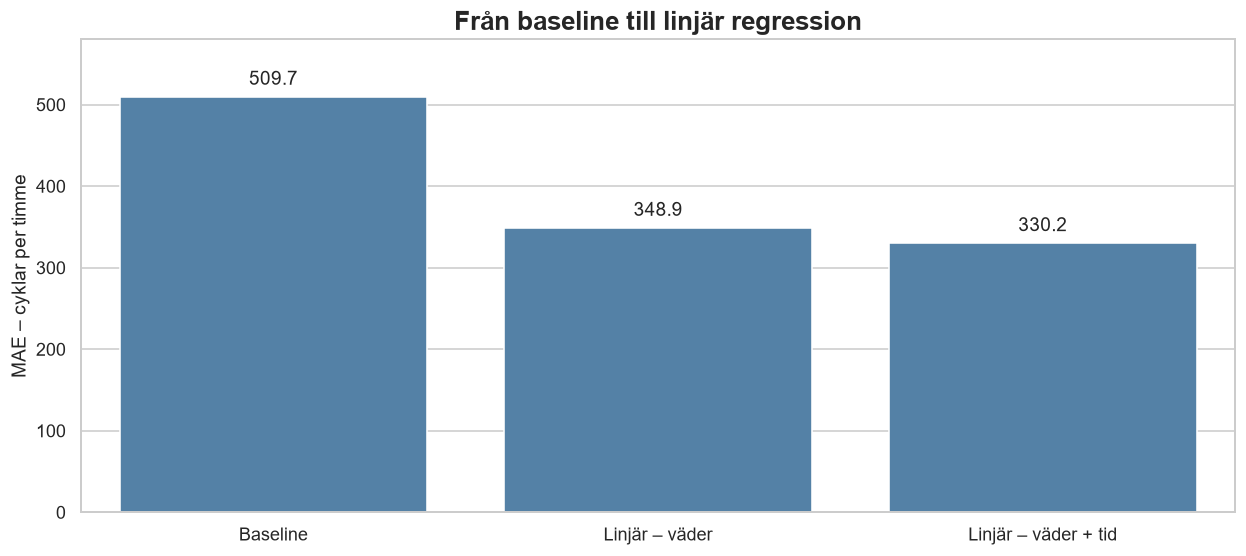

In [ ]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(
    df.loc[train_idx, weather_features],
    y.loc[train_idx]
)

baseline_mae = mean_absolute_error(
    y.loc[test_idx],
    baseline.predict(df.loc[test_idx, weather_features])
)

linear_weather = LinearRegression()
linear_weather.fit(
    df.loc[train_idx, weather_features],
    y.loc[train_idx]
)

linear_weather_mae = mean_absolute_error(
    y.loc[test_idx],
    linear_weather.predict(df.loc[test_idx, weather_features])
)

combined_features = weather_features + ["Hour"]

linear_combined = LinearRegression()
linear_combined.fit(
    df.loc[train_idx, combined_features],
    y.loc[train_idx]
)

linear_combined_mae = mean_absolute_error(
    y.loc[test_idx],
    linear_combined.predict(df.loc[test_idx, combined_features])
)

linear_results = pd.DataFrame({
    "Modell": [
        "Baseline",
        "Linjär – väder",
        "Linjär – väder + tid"
    ],
    "MAE": [
        baseline_mae,
        linear_weather_mae,
        linear_combined_mae
    ]
})

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=linear_results,
    x="Modell",
    y="MAE",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=5)

plt.title("Från baseline till linjär regression", fontsize=16, weight="bold")
plt.ylabel("MAE – cyklar per timme")
plt.xlabel("")
plt.ylim(0, 580)
plt.tight_layout()
plt.show()


### Vad upptäckte vi?

- Cykeluthyrningen har tydliga toppar vid **08 och 18**.
- Sambanden mellan väder, tid och uthyrning är inte alltid linjära.
- En enkel linjär modell kan ha svårt att fånga dessa mönster.

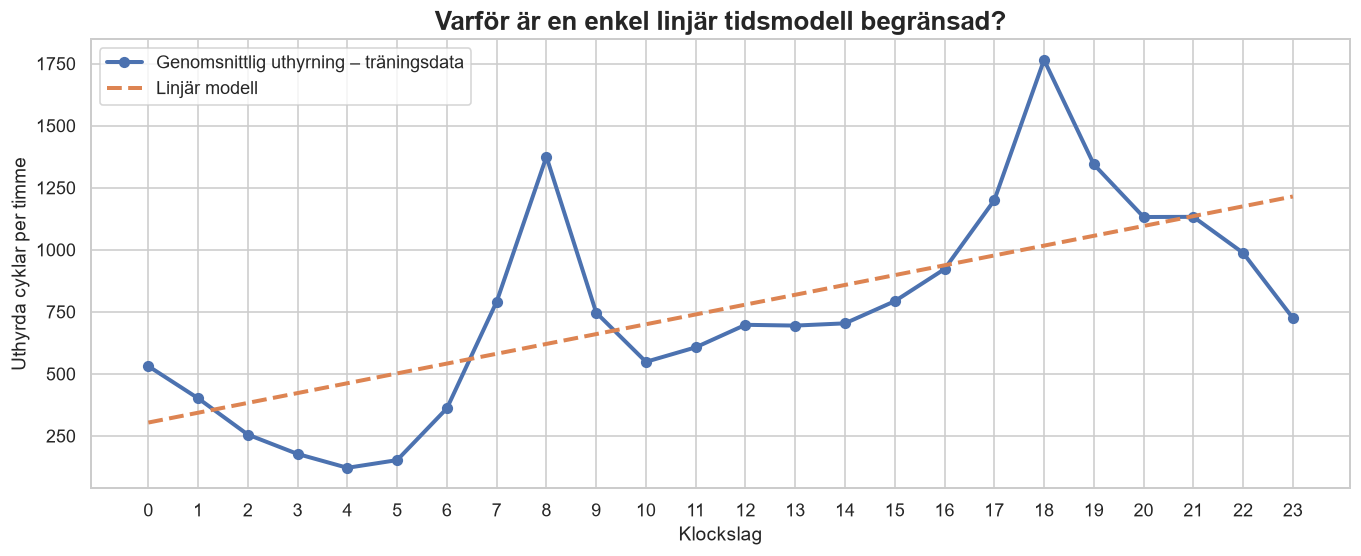

In [10]:

df["Ledig dag"] = (
    (df["Date"].dt.day_of_week >= 5) |
    (df["Holiday"] == "Holiday")
)

X_time = df[["Hour", "Ledig dag"]]

time_model = LinearRegression()
time_model.fit(X_time.loc[train_idx], y.loc[train_idx])

hours = pd.DataFrame({
    "Hour": range(24),
    "Ledig dag": False
})

predicted = time_model.predict(hours)

actual = (
    df.loc[train_idx]
    .loc[lambda data: ~data["Ledig dag"]]
    .groupby("Hour")[target]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    actual.index,
    actual.values,
    marker="o",
    linewidth=2.5,
    label="Genomsnittlig uthyrning – träningsdata"
)

plt.plot(
    range(24),
    predicted,
    linestyle="--",
    linewidth=2.5,
    label="Linjär modell"
)

plt.title("Varför är en enkel linjär tidsmodell begränsad?", fontsize=16, weight="bold")
plt.xlabel("Klockslag")
plt.ylabel("Uthyrda cyklar per timme")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()



## 🌳 Decision Tree

Delar upp datan genom olika beslut och kan fånga icke-linjära samband.

**Test MAE: 222,7**

## 🌲 Random Forest

Kombinerar flera beslutsträd för att göra en gemensam förutsägelse.

**Test MAE: 151,8**




In [11]:

from sklearn.tree import DecisionTreeRegressor

X_train = df.loc[train_idx, combined_features]
X_test = df.loc[test_idx, combined_features]

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

# Decision Tree
decision_tree = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

decision_tree.fit(X_train, y_train)

tree_mae = mean_absolute_error(
    y_test,
    decision_tree.predict(X_test)
)

# Random Forest
random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

forest_mae = mean_absolute_error(
    y_test,
    random_forest.predict(X_test)
)

print(f"Decision Tree MAE: {tree_mae:.1f}")
print(f"Random Forest MAE: {forest_mae:.1f}")


Decision Tree MAE: 222.7
Random Forest MAE: 151.8


### Från baseline till Random Forest

Vi jämför våra modeller med **MAE**.

Alla modeller använder samma testobservationer.

**Lägre MAE = bättre resultat på testdatan.**


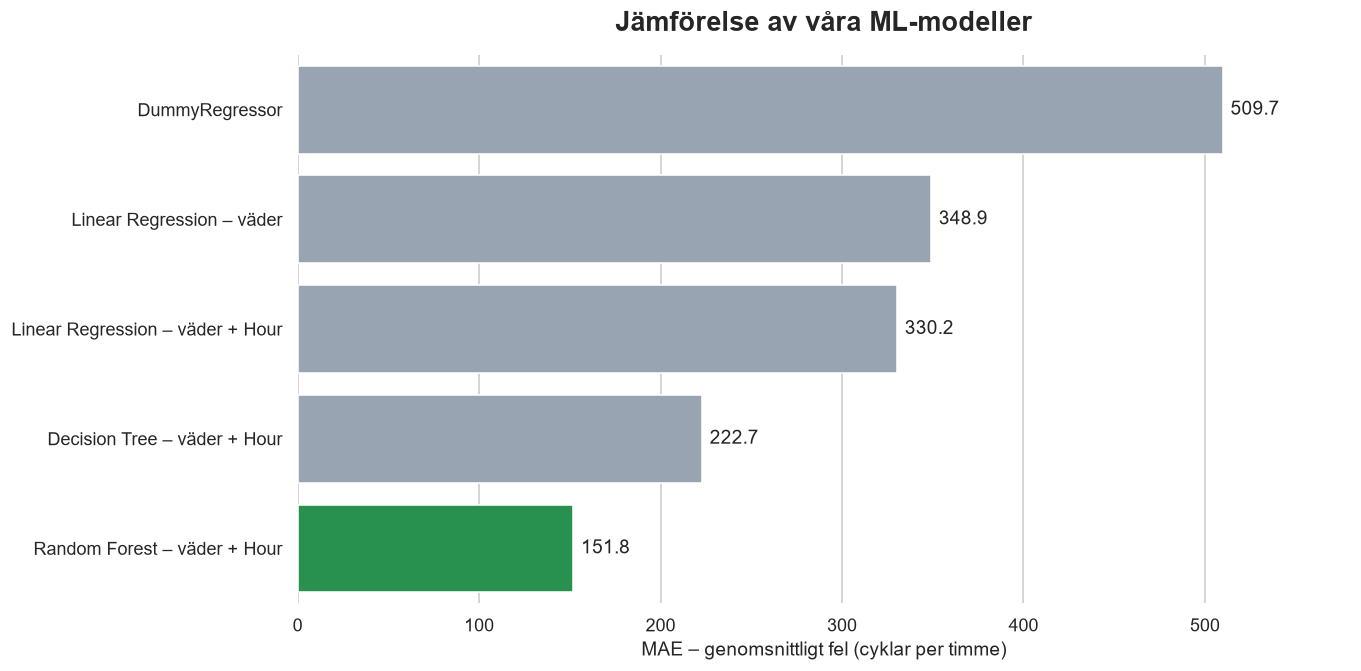

In [12]:

comparison = pd.DataFrame({
    "Modell": [
        "DummyRegressor",
        "Linear Regression – väder",
        "Linear Regression – väder + Hour",
        "Decision Tree – väder + Hour",
        "Random Forest – väder + Hour"
    ],
    "MAE": [
        baseline_mae,
        linear_weather_mae,
        linear_combined_mae,
        tree_mae,
        forest_mae
    ]
})

comparison = comparison.sort_values("MAE", ascending=False)

colors = [
    "#94a3b8" if name != "Random Forest – väder + Hour"
    else "#16a34a"
    for name in comparison["Modell"]
]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=comparison,
    x="MAE",
    y="Modell",
    hue="Modell",
    palette=colors,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=5)

plt.title(
    "Jämförelse av våra ML-modeller",
    fontsize=17,
    fontweight="bold",
    pad=15
)

plt.xlabel("MAE – genomsnittligt fel (cyklar per timme)")
plt.ylabel("")
plt.xlim(0, 580)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()



## Våra observationer

- **Features spelar roll:** Väder och tid förbättrade våra förutsägelser.
- **Algoritmval spelar roll:** Random Forest fångade mer komplexa samband.
- **Lägst testfel:** Random Forest med väder + Hour.

---

# Nästa del: Optimering
